In [ ]:
"""
Logistic Regression in Code: Versicolor vs. Virginica

@author:   Oscar Trevizo
@created:  November 18, 2026
@playlist: https://www.youtube.com/playlist?list=PLJgpRhj3_bvHVST9GVlT3_Su01bp_brLu
@data:     Iris flowers, sns.load_dataset('iris'): petal length and width

Two species that overlap: a logistic regression model that scores 0.85,
the decision boundary as y = mx + b, and the confusion matrix, by hand
(pd.crosstab) and with scikit-learn.
Built on camera in Google Colab.
"""

# Logistic Regression in Code — Part 3: Versicolor vs. Virginica

Two species that overlap: a more realistic case.

In [1]:
# --- Libraries: toolboxes other people wrote ---
import pandas as pd                # tables (DataFrames)
import numpy as np                 # math
import seaborn as sns              # charts, and a few sample datasets
import matplotlib.pyplot as plt    # basic plotting

# scikit-learn (written sklearn in code): Python's main machine-learning library.
# From two of its modules, we import two tools:
from sklearn.model_selection import train_test_split    # a FUNCTION: splits data into train / test
from sklearn.linear_model import LogisticRegression     # a CLASS: the blueprint for a logistic regression model

sns.set_style("darkgrid")

In [2]:
# --- Data: the Iris flowers, as a pandas DataFrame (from video 1a) ---
iris_df = sns.load_dataset('iris')

## Two species: versicolor and virginica

In [3]:
# Keep only the rows where species is not setosa ( != means "not equal" )
two_species_df = iris_df[iris_df['species'] != 'setosa']

two_species_df['species'].value_counts()

,count
species,
versicolor,50
virginica,50


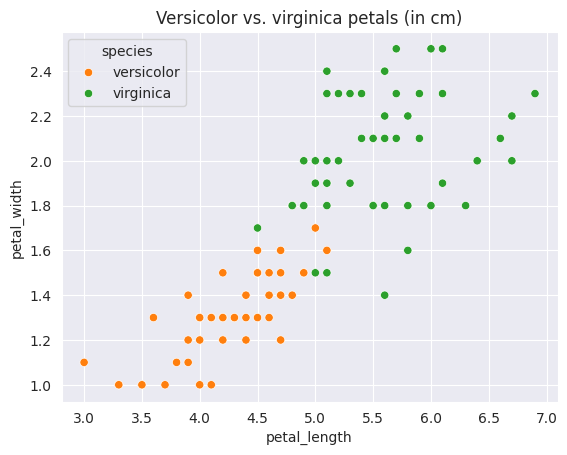

In [4]:
# Same colors as video 1a: versicolor orange, virginica green
sns.scatterplot(
    data=two_species_df,
    x='petal_length',
    y='petal_width',
    hue='species',
    palette={'versicolor': 'tab:orange', 'virginica': 'tab:green'},
)
plt.title('Versicolor vs. virginica petals (in cm)')
plt.show()

## Train / test split

In [5]:
# X = predictors: petal length and petal width
# y = target: versicolor or virginica
X = two_species_df[['petal_length', 'petal_width']]
y = two_species_df['species']

# 80 flowers to learn from, 20 held back to test
x_train, x_test, y_train, y_test = train_test_split(
    X,                  # predictors
    y,                  # target
    test_size=0.2,      # 20% of the flowers go to the test set
    stratify=y,         # same share of each species in both sets
    random_state=40,    # same shuffle every run
)

x_train.shape, x_test.shape

((80, 2), (20, 2))

## Fit and score

In [6]:
petal_lgr = LogisticRegression()
petal_lgr.fit(x_train, y_train)

LogisticRegression()

In [7]:
petal_lgr.score(x_test, y_test)

0.85

## The boundary line: y = mx + b

At p = 0.5, the logit is 0: β0 + β1·length + β2·width = 0.
Solved for width: width = m·length + b, with m = −β1/β2 and b = −β0/β2.

In [8]:
# The model's three numbers
beta0 = petal_lgr.intercept_[0]       # intercept
beta1, beta2 = petal_lgr.coef_[0]     # coefficient for petal length, then petal width

# The boundary line: width = slope_m * length + intercept_b
slope_m = -beta1 / beta2         # slope of the line
intercept_b = -beta0 / beta2     # the LINE's intercept (not the model's intercept_)

print(f"beta0 = {beta0:.2f}   beta1 = {beta1:.2f}   beta2 = {beta2:.2f}")
print(f"m = {slope_m:.2f}   b = {intercept_b:.2f}")

beta0 = -16.81   beta1 = 2.61   beta2 = 2.40
m = -1.09   b = 7.00


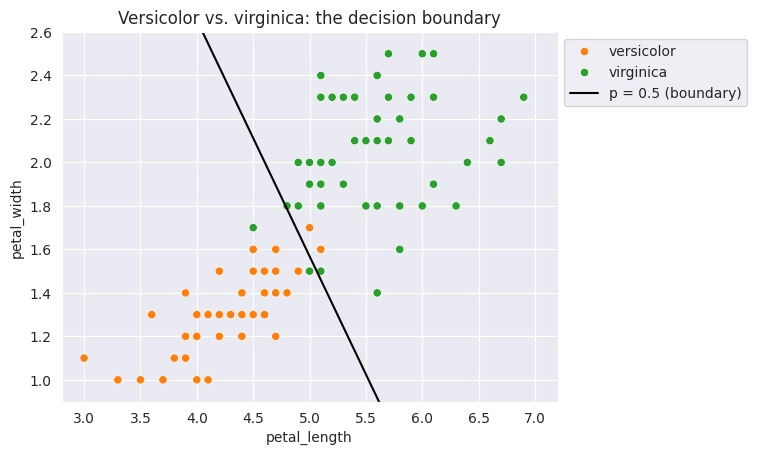

In [9]:
# 100 petal lengths from 3 to 7 cm, and the width on the line for each
length_grid = np.linspace(3, 7, 100)
width_on_line = slope_m * length_grid + intercept_b

# All 100 flowers, plus the line
sns.scatterplot(
    data=two_species_df,
    x='petal_length',
    y='petal_width',
    hue='species',
    palette={'versicolor': 'tab:orange', 'virginica': 'tab:green'},
)
plt.plot(length_grid, width_on_line, color='black', label='p = 0.5 (boundary)')
plt.ylim(0.9, 2.6)       # keep the view on the flowers
plt.title('Versicolor vs. virginica: the decision boundary')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))    # legend outside, to the right
plt.show()

# Part 3b: The Confusion Matrix

Which flowers did the model get wrong, and how?

In [10]:
y_pred = petal_lgr.predict(x_test)

# Actual answers next to the model's predictions
compare_df = pd.DataFrame({'actual': y_test, 'predicted': y_pred})
compare_df

,actual,predicted
97,versicolor,versicolor
51,versicolor,versicolor
69,versicolor,versicolor
60,versicolor,versicolor
77,versicolor,virginica
56,versicolor,versicolor
131,virginica,virginica
134,virginica,virginica
119,virginica,versicolor
81,versicolor,versicolor


In [11]:
# Keep only the rows where the prediction is wrong
compare_df[compare_df['actual'] != compare_df['predicted']]

,actual,predicted
77,versicolor,virginica
119,virginica,versicolor
106,virginica,versicolor


## Binary classification: class 0 and class 1

Two classes, coded 0 and 1. scikit-learn numbers them in alphabetical order (`classes_`).

In [12]:
petal_lgr.classes_

array(['versicolor', 'virginica'], dtype=object)

In [13]:
# Our key: species, its class number, and its confusion-matrix name
class_key_df = pd.DataFrame({
    'species': petal_lgr.classes_,        # in scikit-learn's order
    'class': [0, 1],                      # binary: 0 and 1
    'role': ['negative', 'positive'],     # class 1 = positive
})
class_key_df

,species,class,role
0,versicolor,0,negative
1,virginica,1,positive


## The confusion matrix

Rows: actual. Columns: predicted. The diagonal: correct.

In [14]:
# Count every (actual, predicted) combination
pd.crosstab(y_test, y_pred, rownames=['actual'], colnames=['predicted'])

predicted,versicolor,virginica
actual,,
versicolor,9,1
virginica,2,8


# The Confusion Matrix with scikit-learn

Automating the confusion matrix, and reading it.

In [15]:
from sklearn.metrics import confusion_matrix        # a FUNCTION

confusion_matrix(y_test, y_pred)

array([[9, 1],
       [2, 8]])

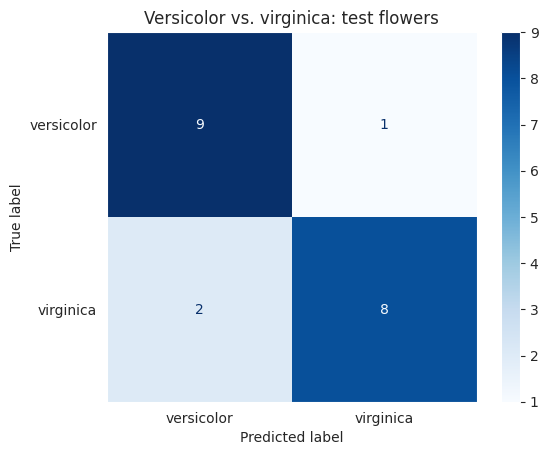

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay  # a CLASS that draws the matrix

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title('Versicolor vs. virginica: test flowers')
plt.grid(False)
plt.show()

### Reading the confusion matrix

Key: versicolor = class 0 = negative, virginica = class 1 = positive.

| | **predicted versicolor** (0, negative) | **predicted virginica** (1, positive) |
|---|---|---|
| **actual versicolor** (0, negative) | **True Negative (TN) = 9** | False Positive (FP) = 1 |
| **actual virginica** (1, positive) | False Negative (FN) = 2 | **True Positive (TP) = 8** |

True / False: was the model right? Positive / Negative: what did the model say?

In [17]:
# Accuracy = (TN + TP) / all test flowers: the diagonal over the total
(9 + 8) / 20

0.85

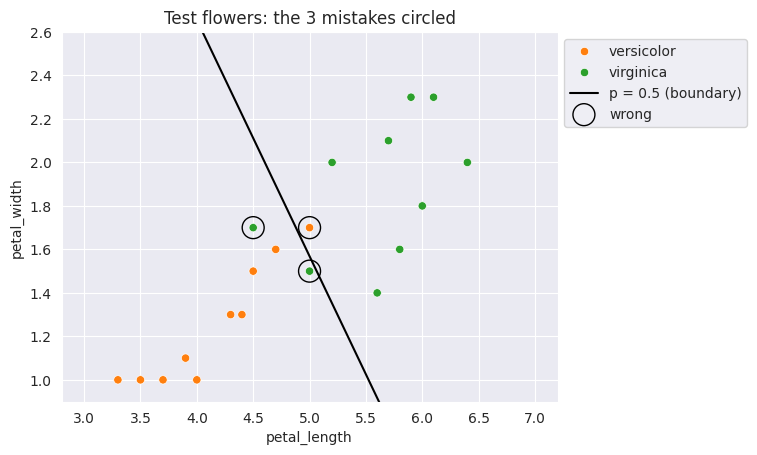

In [18]:
# The 20 test flowers, colored by their TRUE species
sns.scatterplot(
    x=x_test['petal_length'],
    y=x_test['petal_width'],
    hue=y_test,
    palette={'versicolor': 'tab:orange', 'virginica': 'tab:green'},
)
plt.plot(length_grid, width_on_line, color='black', label='p = 0.5 (boundary)')

# Circle the 3 test flowers the model got wrong
wrong = y_test != y_pred      # True where the prediction is wrong
plt.scatter(
    x_test['petal_length'][wrong],
    x_test['petal_width'][wrong],
    s=250,                    # big circles
    facecolors='none',        # hollow
    edgecolors='black',
    label='wrong',
)

plt.ylim(0.9, 2.6)
plt.title('Test flowers: the 3 mistakes circled')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))    # legend outside, to the right
plt.show()